Optimizing Dual Infrastructures (1 Unit/DC)... Strict Target: <=25.0°C
---------------------------------------------------------------------------
Iteration 000 | Total Power: 162.89 kW | Temp A: 23.04°C | Temp B: 24.07°C
Iteration 020 | Total Power: 131.48 kW | Temp A: 24.67°C | Temp B: 24.32°C
Iteration 040 | Total Power: 123.14 kW | Temp A: 24.86°C | Temp B: 24.94°C
Iteration 060 | Total Power: 123.14 kW | Temp A: 24.86°C | Temp B: 24.94°C
Iteration 080 | Total Power: 123.14 kW | Temp A: 24.86°C | Temp B: 24.94°C
Iteration 099 | Total Power: 120.54 kW | Temp A: 24.90°C | Temp B: 24.99°C

DUAL DATACENTER OPTIMIZATION COMPLETE
Combined Total Operational Power: 120.54 kW
Datacenter A Exhaust Temperature: 24.90°C (Load: 220.0 kW)
Datacenter B Exhaust Temperature: 24.99°C (Load: 120.0 kW)

--- DATACENTER A OPTIMAL COOLING SETTINGS ---
 Unit 1 -> Fan Airflow: 75.4%, Temp Setpoint: 18.48°C

--- DATACENTER B OPTIMAL COOLING SETTINGS ---
 Unit 2 -> Fan Airflow: 64.5%, Temp Setpoint: 20.90°C


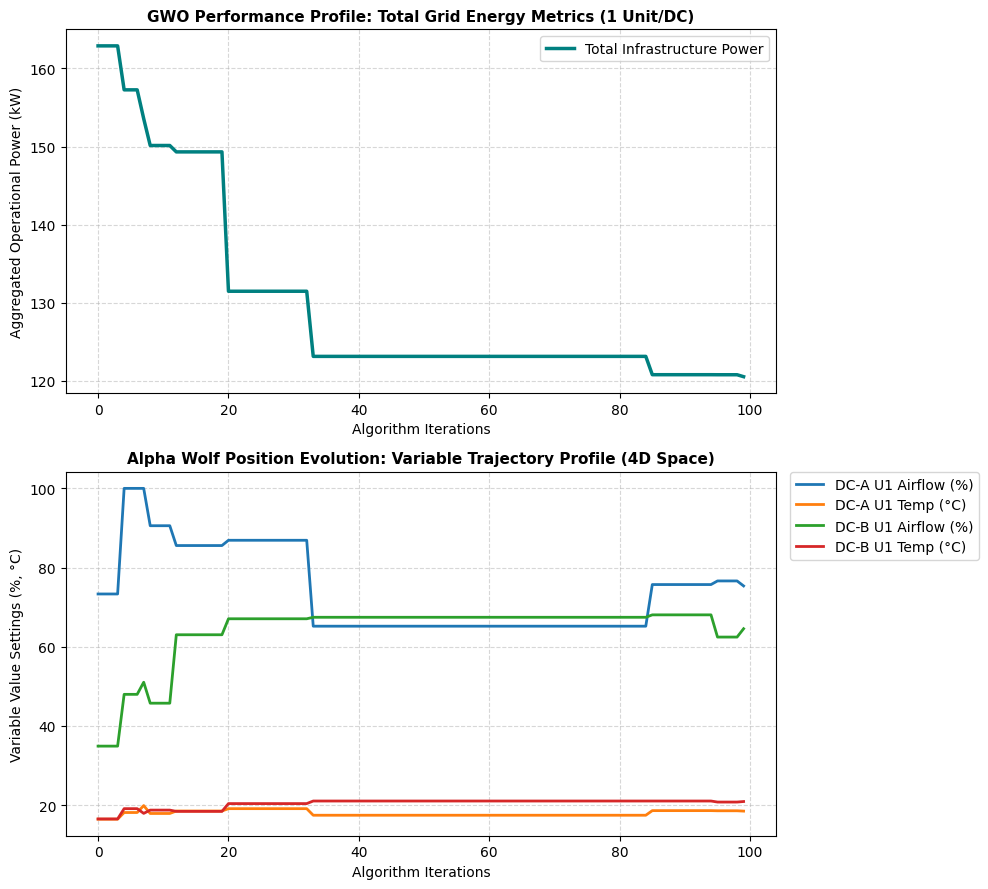

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. DUAL DATACENTER CONFIGURATION (1 UNIT EACH)
# ==========================================
NUM_DC = 2
UNITS_PER_DC = 1
DIMENSIONS = NUM_DC * UNITS_PER_DC * 2 # 4 Dimensions total

# Independent Environmental & Workload Factors
HEAT_LOAD_A = 220.0  # Heavy AI/Compute Load
HEAT_LOAD_B = 120.0  # Light Storage/Cloud Load
SERVER_TEMP_LIMIT = 25.0

# Hardware Limits
AIRFLOW_MIN, AIRFLOW_MAX = 20.0, 100.0
TEMP_MIN, TEMP_MAX = 15.0, 25.0

# Generate 4-dimensional boundary arrays
LOWER_BOUNDS = np.array([AIRFLOW_MIN, TEMP_MIN] * (UNITS_PER_DC * NUM_DC))
UPPER_BOUNDS = np.array([AIRFLOW_MAX, TEMP_MAX] * (UNITS_PER_DC * NUM_DC))

# Variable names for tracking/plotting legends
PARAM_NAMES = [
    "DC-A U1 Airflow (%)", "DC-A U1 Temp (°C)",
    "DC-B U1 Airflow (%)", "DC-B U1 Temp (°C)"
]

# ==========================================
# 2. DUAL-ZONE FITNESS ENGINE (REDUCED SCOPE)
# ==========================================
def evaluate_dual_datacenters(X):
    """
    Evaluates a 4-element cooling configuration for two distinct data centers.
    Returns: (Combined Global Fitness, Temp DC_A, Temp DC_B)
    """
    config_A = X[0:2]
    config_B = X[2:4]

    def calculate_dc_metrics(config, heat_load):
        airflow = config[0]
        temp = config[1]

        # Power calculation models for a single discrete unit
        fan_power = ((airflow / 100.0) ** 3) * 45.0  # Scaled up for single large unit
        chiller_power = (25.0 - temp) * 8.4          # Scaled up for single large unit
        energy = fan_power + chiller_power

        # Thermal mix calculation
        server_temp = temp + (heat_load / (airflow + 1e-5)) * 2.2

        # Local violation penalty
        penalty = 0.0
        if server_temp > SERVER_TEMP_LIMIT:
            penalty = 5000.0 + (server_temp - SERVER_TEMP_LIMIT) * 2500.0

        return energy + penalty, server_temp

    fitness_A, temp_A = calculate_dc_metrics(config_A, HEAT_LOAD_A)
    fitness_B, temp_B = calculate_dc_metrics(config_B, HEAT_LOAD_B)

    return fitness_A + fitness_B, temp_A, temp_B

# ==========================================
# 3. GWO CORE ENGINE (4D SPACE)
# ==========================================
def grey_wolf_optimizer_dual(num_wolves=30, max_iter=100):
    # Lower dimensional space requires fewer wolves and iterations to snap to convergence
    X = np.random.uniform(LOWER_BOUNDS, UPPER_BOUNDS, (num_wolves, DIMENSIONS))

    alpha_pos = np.zeros(DIMENSIONS)
    beta_pos = np.zeros(DIMENSIONS)
    delta_pos = np.zeros(DIMENSIONS)

    alpha_score, beta_score, delta_score = float('inf'), float('inf'), float('inf')

    # History tracking arrays
    fitness_history = []
    alpha_pos_history = []

    print(f"Optimizing Dual Infrastructures (1 Unit/DC)... Strict Target: <={SERVER_TEMP_LIMIT}°C")
    print("-" * 75)

    for t in range(max_iter):
        for i in range(num_wolves):
            X[i] = np.clip(X[i], LOWER_BOUNDS, UPPER_BOUNDS)
            fitness, _, _ = evaluate_dual_datacenters(X[i])

            if fitness < alpha_score:
                alpha_score, beta_score, delta_score = fitness, alpha_score, beta_score
                alpha_pos, beta_pos, delta_pos = X[i].copy(), alpha_pos.copy(), beta_pos.copy()
            elif fitness < beta_score:
                beta_score, delta_score = fitness, beta_score
                beta_pos, delta_pos = X[i].copy(), beta_pos.copy()
            elif fitness < delta_score:
                delta_score = fitness
                delta_pos = X[i].copy()

        a = 2.0 - (2.0 * t / max_iter)

        # 4D Position Translations
        for i in range(num_wolves):
            r1, r2 = np.random.rand(2, DIMENSIONS)
            X1 = alpha_pos - (2.0 * a * r1 - a) * np.abs((2.0 * r2) * alpha_pos - X[i])

            r1, r2 = np.random.rand(2, DIMENSIONS)
            X2 = beta_pos - (2.0 * a * r1 - a) * np.abs((2.0 * r2) * beta_pos - X[i])

            r1, r2 = np.random.rand(2, DIMENSIONS)
            X3 = delta_pos - (2.0 * a * r1 - a) * np.abs((2.0 * r2) * delta_pos - X[i])

            X[i] = (X1 + X2 + X3) / 3.0

        # Append snapshots for graphing
        fitness_history.append(alpha_score)
        alpha_pos_history.append(alpha_pos.copy())

        if t % 20 == 0 or t == max_iter - 1:
            _, t_A, t_B = evaluate_dual_datacenters(alpha_pos)
            print(f"Iteration {t:03d} | Total Power: {alpha_score:.2f} kW | Temp A: {t_A:.2f}°C | Temp B: {t_B:.2f}°C")

    return alpha_pos, alpha_score, fitness_history, np.array(alpha_pos_history)

# ==========================================
# 4. RUN OPTIMIZATION
# ==========================================
best_config, best_power, fit_history, pos_history = grey_wolf_optimizer_dual()
_, final_temp_A, final_temp_B = evaluate_dual_datacenters(best_config)

print("\n" + "="*45 + "\nDUAL DATACENTER OPTIMIZATION COMPLETE\n" + "="*45)
print(f"Combined Total Operational Power: {best_power:.2f} kW")
print(f"Datacenter A Exhaust Temperature: {final_temp_A:.2f}°C (Load: {HEAT_LOAD_A} kW)")
print(f"Datacenter B Exhaust Temperature: {final_temp_B:.2f}°C (Load: {HEAT_LOAD_B} kW)")

print("\n--- DATACENTER A OPTIMAL COOLING SETTINGS ---")
print(f" Unit 1 -> Fan Airflow: {best_config[0]:.1f}%, Temp Setpoint: {best_config[1]:.2f}°C")

print("\n--- DATACENTER B OPTIMAL COOLING SETTINGS ---")
print(f" Unit 2 -> Fan Airflow: {best_config[2]:.1f}%, Temp Setpoint: {best_config[3]:.2f}°C")

# ==========================================
# 5. VISUALIZATION (SINGLE TRAJECTORY GRAPH)
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 9))

# Graph 1: Iterations vs. Fitness (Energy Convergence Summary)
ax1.plot(fit_history, color='teal', linewidth=2.5, label='Total Infrastructure Power')
ax1.set_title('GWO Performance Profile: Total Grid Energy Metrics (1 Unit/DC)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Algorithm Iterations')
ax1.set_ylabel('Aggregated Operational Power (kW)')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Graph 2: Iterations vs. Alpha Positions (Single Trend Trajectory View)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct custom palette for the 4 core parameters
for d in range(DIMENSIONS):
    ax2.plot(pos_history[:, d], color=colors[d], linewidth=2.0, label=PARAM_NAMES[d])

ax2.set_title('Alpha Wolf Position Evolution: Variable Trajectory Profile (4D Space)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Algorithm Iterations')
ax2.set_ylabel('Variable Value Settings (%, °C)')
ax2.grid(True, linestyle='--', alpha=0.5)

# Place the clean 4-element legend on the side
ax2.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=10)

plt.tight_layout()
plt.show()